In [1]:
import os
os.chdir('/home/hedi/HSCNG/')
import numpy as np
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astropy import units as u
import matplotlib.pyplot as plt
import pprint
import pymaster as nmt
from hsc_y3_utils import stats_code
from hsc_y3_utils import map_utils
import tqdm
import multiprocessing as mp
# Using the HSC_Y3_UTILS but not all the pipeline. 
# pipeline
# pixelization -> smoothing -> inpainting -> KSI -> binary mask(use the original mask)

name_fields = ['XMM', 'VVDS','GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches= [8,28,23,7,26,13] # of each corresponding field

tomo_bin = [1, 2, 3, 4]         # tomo_bin, 0 is excluded.
pixscale_arcmin = 0.5   # 0.5 arcmin → degrees/pixel
pixscale_deg = pixscale_arcmin / 60.0
smoothing_kernel_size = 1   # arcmin

_DATA_REAL = {}

for field in name_fields:
    dats_real = [
        fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(number_patches[name_fields.index(field)])
    ]
    dat_real = np.concatenate(dats_real)
    _DATA_REAL[field] = dat_real

In [2]:
def check_dir(directory):
    os.makedirs(directory, exist_ok=True)

def kappa_construct(field, tomo, realization, cone):
    """
    Parameters:
    field: str, one of the name_fields
    tomo: int, tomographic bins of redshift
    realization: str, e.g., '00_a', '00_b', ..., '49_a', '49_b'
    cone: str, e.g., 'cone1', 'cone2', ..., 'cone25'
    """
    global _DATA_REAL, smooth_g, inpainting, smooth_k, overwrite
    # import re
    # assert re.match(r'^\d{2}_[ab]$', realization), "Realization should be in the format '00_a', '00_b', ..., '49_a', '49_b'"
    # assert cone in [f'cone{i}' for i in range(1, 26)], "Cone should be one of 'cone1', 'cone2', ..., 'cone25'"

    procedure = []
    if smooth_g:
        procedure.append('smooth g')
    if inpainting:
        procedure.append('inpainting')
    procedure.append('KSI-masking')
    if smooth_k:
        procedure.append('smooth k')
    procedure_str = '-'.join(procedure)
    np.random.seed(42)

    catalogue_dir = f'data/mock/LCDM_lens/node{realization}/{cone}/'
    outputdir = '/home/hedi/HSCNG/maps/mock/node{}/{}/'.format(realization, cone)
    check_dir(outputdir)
    filename = outputdir + 'kappa_map_mock_{}_z{}_{}.fits'.format(field, tomo, procedure_str)

    if os.path.exists(filename) and not overwrite:
        print(f'{filename} already exists. Skipping...')
        return

    # print(f'Processing field: {field}')

    # print('Loading data...')
    Npatch = number_patches[name_fields.index(field)]
    dats_mock = [
        fits.getdata(catalogue_dir + f'mock_hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat_mock = np.concatenate(dats_mock)
    dat_real = _DATA_REAL[field]

    index = np.isin(dat_real['hsc_y3_zbin'], np.atleast_1d(tomo))

    dat_real = dat_real[index]
    dat_mock = dat_mock[index]

    # --- Input RA/Dec Range (degrees) ---
    ra = dat_real['i_ra']
    dec = dat_real['i_dec']
    padding = 10  # pixels

    w, (nx, ny) = map_utils.set_wcs_shape(ra, dec, pixscale_arcmin, padding)

    # print("Image size:", nx, "x", ny)

    # print('Creating shear and kappa maps...')

    # ---- shear map ----
    flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)

    pix = flatgrid.pos2pix(ra=dat_real['i_ra'], dec=dat_real['i_dec'])
    ra_cat=dat_real['i_ra']
    dec_cat=dat_real['i_dec']
    weight_cat = dat_real['i_hsmshaperegauss_derived_weight']
    m_cat = dat_real['i_hsmshaperegauss_derived_shear_bias_m']
    erms_cat = dat_real['i_hsmshaperegauss_derived_rms_e']

    e1_cat, e2_cat = dat_real['i_hsmshaperegauss_e1'], dat_real['i_hsmshaperegauss_e2']

    flux_cat = dat_real['i_apertureflux_10_mag']
    res_cat = dat_real['i_hsmshaperegauss_resolution']

    # mock ellipticity
    g1_mock, g2_mock = dat_mock['shear1_sim'], dat_mock['shear2_sim']
    kappa_mock = dat_mock['kappa']

    e1_int = np.asarray(dat_mock["noise_int1"])
    e2_int = np.asarray(dat_mock["noise_int2"])
    e1_mea = np.asarray(dat_mock["noise_mea1"])
    e2_mea = np.asarray(dat_mock["noise_mea2"])

    # multiplicative bias
    mhat = np.average(m_cat, weights=weight_cat)

    wsum = np.sum(weight_cat)
    w_ap = np.sum(np.where(flux_cat > 25.5 - 0.025, weight_cat, 0.0))
    w_re = np.sum(np.where(res_cat  < 0.3  + 0.01,  weight_cat, 0.0))

    p_edge_ap = w_ap / wsum
    p_edge_re = w_re / wsum

    # HSC Y3 Eq. (37) https://arxiv.org/pdf/2107.00136
    mselec = -0.05854 * p_edge_ap + 0.01919 * p_edge_re

    # Apply total multiplicative bias
    factor = (1.0 + mhat) * (1.0 + mselec)
    g1_mock *= factor
    g2_mock *= factor

    # ----------------------------------------------------
    # Reduced-shear ellipticity mapping
    # ----------------------------------------------------
    mu = (1.0 - kappa_mock)**2 + g1_mock**2 + g2_mock**2
    d1 = 2.0 * (1.0 - kappa_mock) * g1_mock / mu
    d2 = 2.0 * (1.0 - kappa_mock) * g2_mock / mu

    dnorm = np.sqrt(d1**2 + d2**2)
    try:
        with np.errstate(divide='raise', invalid='raise'):
            corr1 = (d2 / dnorm**2) * (1.0 - np.sqrt(1.0 - dnorm**2)) * (d1 * e2_int - d2 * e1_int)
            corr2 = (d1 / dnorm**2) * (1.0 - np.sqrt(1.0 - dnorm**2)) * (d2 * e1_int - d1 * e2_int)

    except:
        print(field, tomo, realization, cone)
        return
    # corr1[np.isnan(corr1)] = 0.0
    # corr2[np.isnan(corr2)] = 0.0            # there exists devide by zero problems here.

    # # Miralda-Escudé (1991); http://adsabs.harvard.edu/abs/1991ApJ...380....1M   
    e1_mock = (
        e1_int + d1 + corr1
    ) / (1.0 + d1 * e1_int + d2 * e2_int)

    e2_mock = (
        e2_int + d2 + corr2
    ) / (1.0 + d1 * e1_int + d2 * e2_int)

    # Add measurement noise
    e1_mock += e1_mea
    e2_mock += e2_mea

    if (np.abs(e1_mock) > 10).any() or (np.abs(e2_mock) > 10).any():
        print(field, tomo, realization, cone)
        return

    # e1_cat, e2_cat = e1_mock, e2_mock

    # c1_cat = c2_cat = np.zeros_like(e1_cat)  # no additive bias in the mock data, so set to zero
    # epsf1_cat = epsf2_cat = np.zeros_like(e1_cat)  # no PSF anisotropy in the mock data, so set to zero

    # # all kinds of calibrations and selection effect corrections
    # e1_hat, e2_hat =  map_utils.calib_shear_y3(weight_cat, m_cat, erms_cat, e1_cat, e2_cat, c1_cat, c2_cat, flux_cat, res_cat, epsf1_cat, epsf2_cat)


    # # weighted averaged shear map
    # # kappa map

    # # pixelize shear map
    # [g1_map, g2_map], [mask, nmap], weightsmap = map_utils.create_shear_map(ra_cat, dec_cat, e1_hat, e2_hat, flatgrid, weights=weight_cat, return_weightsmap=True)
    # # questions here: the mask shows whether there is galaxy, but we dont use the weight map afterwards.
    # mask_z = flatgrid.transform_mapsize(mask)
    # g1_map = flatgrid.transform_mapsize(g1_map)
    # g2_map = flatgrid.transform_mapsize(g2_map)

    # smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)          # should be 2 here.

    # _g1_map = g1_map
    # _g2_map = g2_map
    # # smoothing
    # if smooth_g:
    #     _g1_map = flatgrid.smooth_G_masked(g1_map, mask_z, smoothing_pixels)      # smoothed g1 map, 2d
    #     _g2_map = flatgrid.smooth_G_masked(g2_map, mask_z, smoothing_pixels)
    #     # g1_map = flatgrid.smooth_G(g1_map, smoothing_pixels)      # smoothed g1 map, 2d
    #     # g2_map = flatgrid.smooth_G(g2_map, smoothing_pixels)
    # if inpainting:      # maybe consider moving inpainting to the front, and then do smoothing
    # # Inpainting
    #     _g1_map = map_utils.inpaint(_g1_map*mask_z, mask_z, niter=100, thresholding='hard')
    #     _g2_map = map_utils.inpaint(_g2_map*mask_z, mask_z, niter=100, thresholding='hard')

    # # KS inversion
    # kappa, kappa_i = map_utils.KS_map(_g1_map, _g2_map)
    # if smooth_k:
    #     kappa = flatgrid.smooth_G(kappa, smoothing_pixels)          # E mode
    #     kappa_i = flatgrid.smooth_G(kappa_i, smoothing_pixels)      # B mode

    # # print('save kappa map...')
    # header = flatgrid.wcs.to_header()
    # hdulist = fits.HDUList([fits.PrimaryHDU(header=header)])

    # maps = [
    #     ("G1", g1_map),
    #     ("G2", g2_map),
    #     ("KAPPA", kappa),
    #     ("KAPPA_I", kappa_i),
    #     ("WEIGHT_MASK", weightsmap),
    #     ("NMAP", nmap),
    # ]

    # for name, data in maps:
    #     hdu = fits.ImageHDU(data=flatgrid.transform_mapsize(data), header=header, name=name)
    #     hdu.header["MAPNAME"] = name
    #     hdulist.append(hdu)

    # hdulist.writeto(filename, overwrite=True)

In [19]:
np.random.seed(42)

def load_data(field, realization, cone, tomo=None):
    global _DATA_REAL
    catalogue_dir = f'data/mock/LCDM_lens/node{realization}/{cone}/'

    # print(f'Processing field: {field}')

    # print('Loading data...')
    Npatch = number_patches[name_fields.index(field)]
    dats_mock = [
        fits.getdata(catalogue_dir + f'mock_hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat_mock = np.concatenate(dats_mock)
    dat_real = _DATA_REAL[field]
    if tomo is not None:
        index = np.isin(dat_real['hsc_y3_zbin'], np.atleast_1d(tomo))
        dat_real = dat_real[index]
        dat_mock = dat_mock[index]
    return dat_mock, dat_real

from astropy.table import Table, vstack
def get_fiducial_catalog(field, n_sim):     # no tomo binning here.
    import glob

    files = sorted(glob.glob(
        f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/'
        f'fiducial_catalog_chopped/cat_fiducial_{field}_nsim_{n_sim}_chooped_n_*.fits'
    ))
    tabs = []
    for f in files:
        tab = Table.read(f)
        tabs.append(tab)
        # print(f, len(tab))
    return vstack(tabs)

def get_real_catalog(field):
    name_fields = ['XMM', 'VVDS','GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
    number_patches= [8, 25,23,7,26,13] # of each corresponding field
    Npatch = number_patches[name_fields.index(field)]
    dats = [
        Table.read(f'data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = vstack(dats)
    return dat

In [54]:
import glob
files = sorted(glob.glob(
    f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/'
    f'fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_*.fits'
))

In [62]:
for f in name_fields:
    print(f, len(glob.glob(
        f'data/real/hscy3_shape_chopped_{f}_*.fits'
    )))

XMM 8
VVDS 28
GAMA09H 23
GAMA15H 7
WIDE12H 26
HECTOMAP 13


In [55]:
files

['/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_0.fits',
 '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_1.fits',
 '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_10.fits',
 '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_11.fits',
 '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_12.fits',
 '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_13.fits',
 '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_14.fits',
 '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/fiducial_catalog_chopped/cat_fiducial_VVDS_nsim_0_chooped_n_15.fits',
 '/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/f

In [53]:
get_fiducial_catalog('VVDS', 0)

tract_id,irow_in_original_fits_file,object_id,ra_mock,dec_mock,e1_mock,e2_mock,shear1_sim,shear2_sim,kappa,noise1_int,noise2_int,noise1_mea,noise2_mea,weight,z_source_mock
int64,int64,int64,float64,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float64,float32
9449,164,41557162958262300,331.0259,-0.5605311000000001,0.69666135,-0.4638132,-0.0065097813,0.00052091945,-0.004662037,0.6921922,-0.274527,0.011081551,-0.18778704,4.375089,0.6425
9449,165,41557162958262341,331.0385,-0.5596281,-0.5872203,-0.46278405,-0.0014097079,-0.0010844364,-0.00019216537,-0.31280038,-0.5360983,-0.27224413,0.07438342,3.335245,0.2657
9449,173,41557162958262652,331.0291,-0.5524688,-0.3364391,-0.32506356,-0.014397681,-0.011497701,-0.00058698654,-0.24077158,-0.18138166,-0.06985977,-0.122945525,6.534828,0.6425
9449,297,41557162958265358,331.02660000000003,-0.4933575,0.8179641,-0.25075722,-0.0045699305,-0.01889506,-0.005948901,0.65775037,-0.22117816,0.17130575,0.007250582,5.222335,0.714
9449,303,41557162958265509,331.0251,-0.49037620000000004,0.17622675,0.32326216,-0.0145979235,-0.025854835,-0.01868534,0.06692381,0.41148502,0.13682827,-0.04579392,4.957286,1.1233
9449,304,41557162958265544,331.0271,-0.48948270000000005,0.13436115,0.46772286,-0.003436988,-0.009119241,-0.0011761189,0.2574187,0.46922627,-0.11879,0.012006468,7.815878,0.5078
9449,307,41557162958265628,331.03020000000004,-0.48768,-0.52697897,-0.55552524,-0.009584895,-0.020280654,-0.014103768,-0.48461637,-0.5460356,-0.038777016,0.012958769,5.33137,0.9479
9449,324,41557162958265924,331.0247,-0.48069080000000003,-0.2784277,-0.6509534,-0.005304655,-0.01625624,-0.009655714,-0.31765297,-0.58442456,0.0425543,-0.047678173,6.667673,0.714
9449,574,41557162958279726,331.0277,-0.5675865,0.35198757,0.58476174,-0.027670203,0.0048959735,-0.003706932,0.24121149,0.5697074,0.16458385,0.0017262552,4.93785,1.3176


In [4]:
dat_mock, dat_real = load_data('GAMA09H', '00_a', 'cone1')

In [42]:
dat_fid = get_fiducial_catalog('GAMA09H', 100)

In [21]:
dat_real = get_real_catalog('GAMA09H')

In [27]:
dat_real_tomo = dat_real[['object_id', 'hsc_y3_zbin']]

In [29]:
from astropy.table import join

In [45]:
tab_fid_with_tomo = join(dat_fid, dat_real_tomo, keys='object_id', join_type='left')        # there are some unmatched object_ids.

In [51]:
dat_fid

tract_id,irow_in_original_fits_file,object_id,ra_mock,dec_mock,e1_mock,e2_mock,shear1_sim,shear2_sim,kappa,noise1_int,noise2_int,noise1_mea,noise2_mea,weight,z_source_mock
int64,int64,int64,float64,float64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float64,float32
9070,1,39890316215452290,128.6644,-1.564789,0.120290175,0.10615047,0.00029748643,-6.60489e-05,0.000597824,0.118259445,0.09939301,0.0014422138,0.0068953456,6.259038,0.0506
9070,2,39890316215452315,128.6709,-1.564257,-0.10868998,-0.5147767,-0.00039268,-0.046096005,-0.00021853224,-0.13689674,-0.2823121,0.024936114,-0.1499943,3.455404,3.3932
9070,3,39890316215452446,128.66710000000003,-1.560773,0.26420516,-0.11632241,-0.00016263872,-0.00031665488,0.0004989708,0.0032396312,-0.34617084,0.26129165,0.23040636,3.562776,0.0506
9070,4,39890316215452572,128.67649999999998,-1.557048,0.18765572,-0.7208742,-0.012180966,0.0030811925,-0.011220974,0.15764844,-0.6629531,0.052994106,-0.05900808,5.05096,0.9479
9070,5,39890316215452695,128.6637,-1.55394,0.12870184,0.15929434,-0.011216479,-0.0005812145,-0.008948973,-0.14820217,0.3083123,0.29863167,-0.14688784,4.846996,0.7885
9070,6,39890316215452797,128.6687,-1.5512200000000003,-0.46145225,-0.35655373,-0.0015388958,0.0031043144,0.0019195636,-0.55658704,-0.17111865,0.09784138,-0.19176917,4.501374,0.2657
9070,7,39890316215453104,128.66309999999996,-1.542494,0.25187087,-0.12114961,0.0044134697,0.004263306,-0.005814239,0.28949666,-0.21615113,-0.046171904,0.086358495,5.099418,0.9479
9070,8,39890316215453114,128.6744,-1.542261,0.13311139,-0.85008264,0.011921317,9.171369e-05,0.0031825395,0.09622931,-0.25907356,0.0132374745,-0.5918493,3.511781,1.6528
9070,9,39890316215453344,128.6672,-1.5361110000000002,0.47828925,-0.36216298,0.011125327,0.0017173623,-0.01561618,0.15490189,-0.2631459,0.30193368,-0.10311598,5.004401,1.6528


In [6]:
print(np.nanmin(dat_mock['e1_mock_with_zero_m']), np.nanmax(dat_mock['e1_mock_with_zero_m']))
print(np.nanmin(dat_mock['e2_mock_with_zero_m']), np.nanmax(dat_mock['e2_mock_with_zero_m']))

-1e+10 12.494507
-1e+10 2.4776387


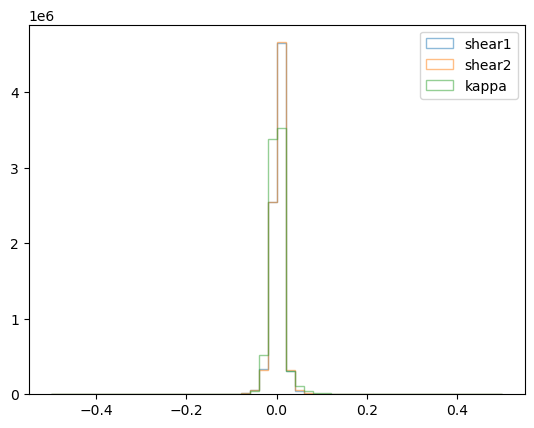

In [7]:
plt.hist(dat_mock['shear1_sim'], bins=50, range=(-0.5, 0.5), alpha=0.5, label='shear1', histtype='step')
plt.hist(dat_mock['shear2_sim'], bins=50, range=(-0.5, 0.5), alpha=0.5, label='shear2', histtype='step')
plt.hist(dat_mock['kappa'], bins=50, range=(-0.5, 0.5), alpha=0.5, label='kappa', histtype='step')
plt.legend()
plt.show()

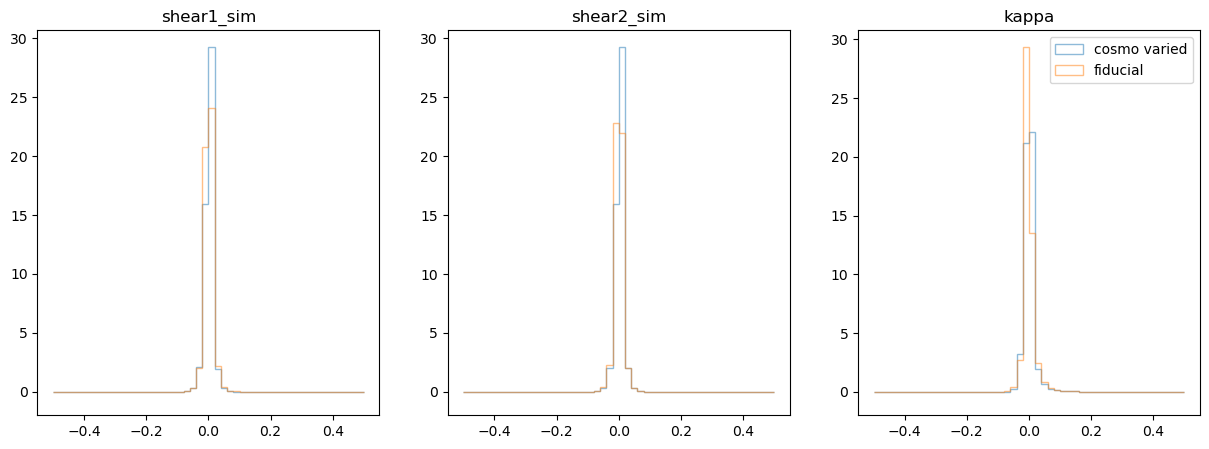

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].hist(dat_mock['shear1_sim'], bins=50, range=(-0.5, 0.5), alpha=0.5, label='cosmo varied', histtype='step', density=True)
axs[0].hist(dat_fid['shear1_sim'][dat_fid['shear1_sim'] > -10], bins=50, range=(-0.5, 0.5), alpha=0.5, label='fiducial', histtype='step', density=True)
axs[0].set_ylim(bottom=-2)
axs[0].set_title('shear1_sim')

axs[1].hist(dat_mock['shear2_sim'], bins=50, range=(-0.5, 0.5), alpha=0.5, label='cosmo varied', histtype='step', density=True)
axs[1].hist(dat_fid['shear2_sim'][dat_fid['shear2_sim'] > -10], bins=50, range=(-0.5, 0.5), alpha=0.5, label='fiducial', histtype='step', density=True)
axs[1].set_ylim(bottom=-2)
axs[1].set_title('shear2_sim')

axs[2].hist(dat_mock['kappa'], bins=50, range=(-0.5, 0.5), alpha=0.5, label='cosmo varied', histtype='step', density=True)
axs[2].hist(dat_fid['kappa'][dat_fid['kappa'] > -10], bins=50, range=(-0.5, 0.5), alpha=0.5, label='fiducial', histtype='step', density=True)
axs[2].set_ylim(bottom=-2)
axs[2].set_title('kappa')

plt.legend()
plt.show()

all data
e1_mock_with_zero_m -1e+10 12.494507
e2_mock_with_zero_m -1e+10 2.4776387
tomo bin: 1
e1_mock_with_zero_m -2.1431084 2.2878573
e2_mock_with_zero_m -2.1104348 1.9892023
tomo bin: 2
e1_mock_with_zero_m -2.284134 2.397144
e2_mock_with_zero_m -2.2611938 2.4776387
tomo bin: 3
e1_mock_with_zero_m -2.291685 12.494507
e2_mock_with_zero_m -24.226414 2.1655993
tomo bin: 4
e1_mock_with_zero_m -2.4880323 2.398578
e2_mock_with_zero_m -2.645724 2.3538077


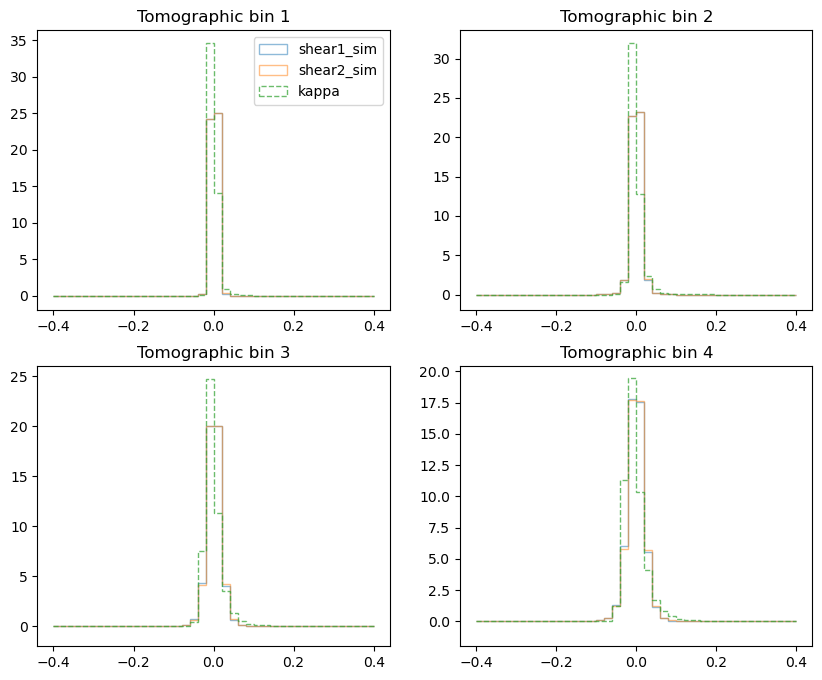

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()
print('all data')
print('e1_mock_with_zero_m', np.nanmin(dat_mock['e1_mock_with_zero_m']), np.nanmax(dat_mock['e1_mock_with_zero_m']))
print('e2_mock_with_zero_m', np.nanmin(dat_mock['e2_mock_with_zero_m']), np.nanmax(dat_mock['e2_mock_with_zero_m']))
for tomo in range(1, 5):
    index = np.isin(dat_real['hsc_y3_zbin'], np.atleast_1d(tomo))
    dat_mock1 = dat_mock[index]
    axes[tomo-1].hist(dat_mock1['shear1_sim'], bins=40, range=(-0.4, 0.4), alpha=0.5, label='shear1_sim', histtype='step', density=True)
    axes[tomo-1].hist(dat_mock1['shear2_sim'], bins=40, range=(-0.4, 0.4), alpha=0.5, label='shear2_sim', histtype='step', density=True)
    axes[tomo-1].hist(dat_mock1['kappa'], bins=40, range=(-0.4, 0.4), alpha=0.7, label='kappa', histtype='step', linestyle='--', density=True)
    axes[tomo-1].set_title(f'Tomographic bin {tomo}')
    axes[tomo-1].set_ylim(bottom=-2)
    print('tomo bin:', tomo)
    print('e1_mock_with_zero_m', np.nanmin(dat_mock1['e1_mock_with_zero_m']), np.nanmax(dat_mock1['e1_mock_with_zero_m']))
    print('e2_mock_with_zero_m', np.nanmin(dat_mock1['e2_mock_with_zero_m']), np.nanmax(dat_mock1['e2_mock_with_zero_m']))
axes[0].legend()
plt.show()

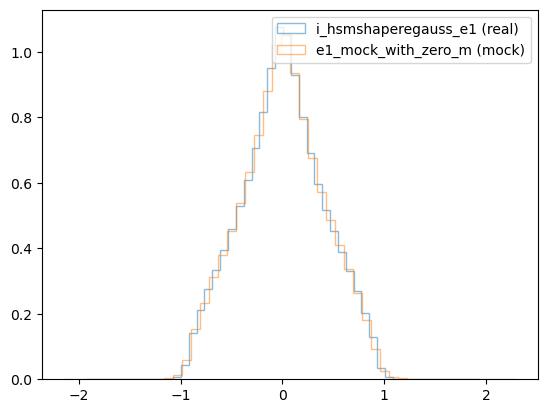

In [61]:
tomo = 1
index = np.isin(dat_real['hsc_y3_zbin'], np.atleast_1d(tomo))
dat_mock1 = dat_mock[index]
dat_real1 = dat_real[index]
plt.hist(dat_real1['i_hsmshaperegauss_e1'], bins=50, alpha=0.5, label='i_hsmshaperegauss_e1 (real)', histtype='step', density=True)
plt.hist(dat_mock1['e1_mock_with_zero_m'], bins=50, alpha=0.5, label='e1_mock_with_zero_m (mock)', histtype='step', density=True)
plt.legend(loc='upper right')
plt.show()

In [9]:
print(np.min(dat_mock['kappa']), np.max(dat_mock['kappa']))

-0.10506043 1.0994849


In [10]:
dat_mock, dat_real = load_data('GAMA09H', '00_a', 'cone1', tomo=1)


# --- Input RA/Dec Range (degrees) ---
ra = dat_real['i_ra']
dec = dat_real['i_dec']
padding = 10  # pixels

w, (nx, ny) = map_utils.set_wcs_shape(ra, dec, pixscale_arcmin, padding)

# print("Image size:", nx, "x", ny)

# print('Creating shear and kappa maps...')

# ---- shear map ----
flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)

pix = flatgrid.pos2pix(ra=dat_real['i_ra'], dec=dat_real['i_dec'])
ra_cat=dat_real['i_ra']
dec_cat=dat_real['i_dec']
weight_cat = dat_real['i_hsmshaperegauss_derived_weight']
m_cat = dat_real['i_hsmshaperegauss_derived_shear_bias_m']
erms_cat = dat_real['i_hsmshaperegauss_derived_rms_e']

e1_cat, e2_cat = dat_real['i_hsmshaperegauss_e1'], dat_real['i_hsmshaperegauss_e2']

flux_cat = dat_real['i_apertureflux_10_mag']
res_cat = dat_real['i_hsmshaperegauss_resolution']

# mock ellipticity
g1_mock, g2_mock = dat_mock['shear1_sim'], dat_mock['shear2_sim']
kappa_mock = dat_mock['kappa']

e1_int = np.asarray(dat_mock["noise_int1"])
e2_int = np.asarray(dat_mock["noise_int2"])
e1_mea = np.asarray(dat_mock["noise_mea1"])
e2_mea = np.asarray(dat_mock["noise_mea2"])

# multiplicative bias
mhat = np.average(m_cat, weights=weight_cat)

wsum = np.sum(weight_cat)
w_ap = np.sum(np.where(flux_cat > 25.5 - 0.025, weight_cat, 0.0))
w_re = np.sum(np.where(res_cat  < 0.3  + 0.01,  weight_cat, 0.0))

p_edge_ap = w_ap / wsum
p_edge_re = w_re / wsum

# HSC Y3 Eq. (37) https://arxiv.org/pdf/2107.00136
mselec = -0.05854 * p_edge_ap + 0.01919 * p_edge_re

# Apply total multiplicative bias
factor = (1.0 + mhat) * (1.0 + mselec)
g1_mock *= factor
g2_mock *= factor

# ----------------------------------------------------
# Reduced-shear ellipticity mapping
# ----------------------------------------------------
mu = (1.0 - kappa_mock)**2 + g1_mock**2 + g2_mock**2
d1 = 2.0 * (1.0 - kappa_mock) * g1_mock / mu
d2 = 2.0 * (1.0 - kappa_mock) * g2_mock / mu

dnorm = np.sqrt(d1**2 + d2**2)
with np.errstate(divide='raise', invalid='raise'):
    corr1 = (d2 / dnorm**2) * (1.0 - np.sqrt(1.0 - dnorm**2)) * (d1 * e2_int - d2 * e1_int)
    corr2 = (d1 / dnorm**2) * (1.0 - np.sqrt(1.0 - dnorm**2)) * (d2 * e1_int - d1 * e2_int)

corr1[np.isnan(corr1)] = 0.0
corr2[np.isnan(corr2)] = 0.0            # there exists devide by zero problems here.

# Miralda-Escudé (1991); http://adsabs.harvard.edu/abs/1991ApJ...380....1M   
e1_mock = (
    e1_int + d1 + corr1
) / (1.0 + d1 * e1_int + d2 * e2_int)

e2_mock = (
    e2_int + d2 + corr2
) / (1.0 + d1 * e1_int + d2 * e2_int)

# Add measurement noise
e1_mock += e1_mea
e2_mock += e2_mea

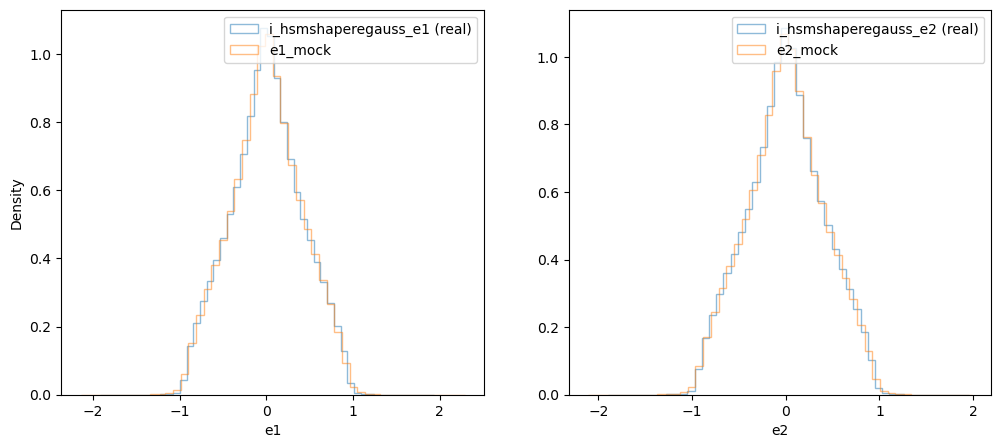

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.hist(dat_real['i_hsmshaperegauss_e1'], bins=50, alpha=0.5, label='i_hsmshaperegauss_e1 (real)', histtype='step', density=True)
ax.hist(e1_mock, bins=50, alpha=0.5, label='e1_mock', histtype='step', density=True)
ax.legend(loc='upper right')
ax.set_xlabel('e1')
ax.set_ylabel('Density')

ax = axes[1]
ax.hist(dat_real['i_hsmshaperegauss_e2'], bins=50, alpha=0.5, label='i_hsmshaperegauss_e2 (real)', histtype='step', density=True)
ax.hist(e2_mock, bins=50, alpha=0.5, label='e2_mock', histtype='step', density=True)
ax.legend(loc='upper right')
ax.set_xlabel('e2')

plt.show()

In [ ]:
# import os
# for i_cosmo in range(50):
#     for phase in ['a', 'b']:
#         for cone in [f'cone{i}' for i in range(1, 26)]:
#             realization = '{:02d}_{}'.format(i_cosmo, phase)
#             path = '/home/hedi/HSCNG/maps/mock/node{}/{}/'.format(realization, cone)
#             assert len(os.listdir(path)) == 24
#             for i in range(1, 5):
#                 os.rename(f'{path}kappa_map_mock_VVDS_z{i}_smooth g-inpainting-KSI-masking.fits', 
#                           f'{path}kappa_map_mock_VVDS_25_z{i}_smooth g-inpainting-KSI-masking.fits')        # rename VVDS

In [3]:
name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
_GALAXY_COUNTS_TOMOBIN_ = {}

for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'~/HSCNG/data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    _numbers = []
    for tomo_bin in [1, 2, 3, 4]:
        _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
    _GALAXY_COUNTS_TOMOBIN_[field] = _numbers

In [4]:
Cl_tomo_g = []
Cl_tomo_di = []

for tomo in [1, 2, 3, 4]:
    Cl_cosmo_varied_g = []
    Cl_cosmo_varied_di = []
    for cosmology_id in range(50):
        Cls_g = []
        Cls_di = []
        for field in name_fields:
            dat_g = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/power_spectrum/model{cosmology_id}_Clee_z{tomo}_{field}.npy')     # 50 realizations here
            dat_di = np.load(f'/home/hedi/HSCNG/power/mock_results/model{cosmology_id}_power_z{tomo}_{field}.npy')     # 50 realizations here
            Cls_g.append(dat_g)
            Cls_di.append(dat_di)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        Cl_cosmo_varied_g.append(np.average(Cls_g, axis=0, weights=weights))
        Cl_cosmo_varied_di.append(np.average(Cls_di, axis=0, weights=weights))

    Cl_tomo_g.append(Cl_cosmo_varied_g)
    Cl_tomo_di.append(Cl_cosmo_varied_di)

Cl_tomo_g = np.array(Cl_tomo_g)
Cl_tomo_di = np.array(Cl_tomo_di)

In [36]:
cosmology_id = 0
tomo = 2
field = 'XMM'

dat_g = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/power_spectrum/model{cosmology_id}_Clee_z{tomo}_{field}.npy')     # 50 realizations here
dat_di = np.load(f'/home/hedi/HSCNG/power/mock_results/model{cosmology_id}_power_z{tomo}_{field}.npy')     # 50 realizations here
dat_fid = np.load(f'/home/hedi/HSCNG/power/fid_results/fid_power_z{tomo}_{field}.npy')
dat_fid_legacy = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_fiducial/power_spectrum/Clee_z{tomo}_{field}.npy')

In [37]:
l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
xx_g = binner.get_effective_ells()

l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500), 20))
binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
xx_di = binner.get_effective_ells()

Text(0.5, 1.0, 'Power spectrum XMM z2')

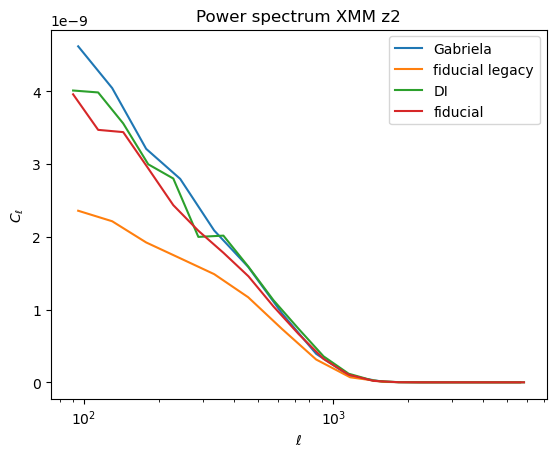

In [38]:
plt.plot(xx_g, dat_g.mean(axis=0), label='Gabriela')
plt.plot(xx_g, dat_fid_legacy.mean(axis=0), label='fiducial legacy')
plt.plot(xx_di, dat_di.mean(axis=0), label='DI')
plt.plot(xx_di, dat_fid.mean(axis=0), label='fiducial')

plt.xlabel('$\\ell$')
plt.ylabel('$C_\\ell$')
plt.legend()
plt.semilogx()

plt.title(f'Power spectrum {field} z{tomo}')

In [39]:
cosmology_id = 0
tomo = 2
field = 'XMM'

dat_di_cosmo_varied = [np.load(f'/home/hedi/HSCNG/power/mock_results/model{cosmology_id}_power_z{tomo}_{field}.npy').mean(axis=0) for cosmology_id in range(50)]
dat_fid = np.load(f'/home/hedi/HSCNG/power/fid_results/fid_power_z{tomo}_{field}.npy')
dat_fid_legacy = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_fiducial/power_spectrum/Clee_z{tomo}_{field}.npy')

Text(0.5, 1.0, 'Power spectrum XMM z2 (DI)')

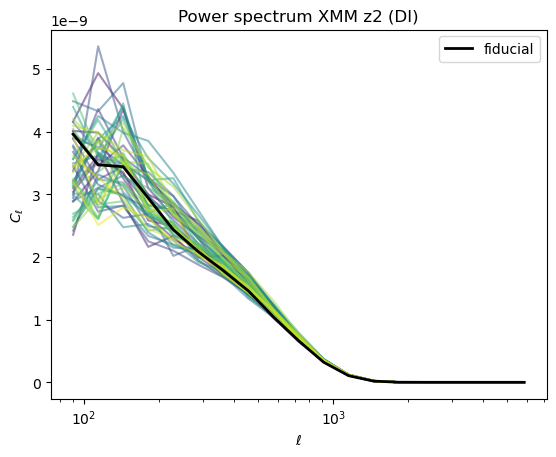

In [45]:
cmap = plt.get_cmap('viridis')
for i in range(len(dat_di_cosmo_varied)):
    plt.plot(xx_di, dat_di_cosmo_varied[i], alpha=0.5, color=cmap(i / len(dat_di_cosmo_varied)))
plt.plot(xx_di, dat_fid.mean(axis=0), label='fiducial', color='black', linewidth=2)
plt.xlabel('$\\ell$')
plt.ylabel('$C_\\ell$')
plt.legend()
plt.semilogx()
plt.title(f'Power spectrum {field} z{tomo} (DI)')